<a href="https://colab.research.google.com/github/BSsangani/How-Data-Quality-Affects-Energy-Demand-Forecasting-in-UK-Smart-Grids/blob/main/Step1_DataCollection_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Step 1: NESO Demand Data - Download, Clean and Explore

Before I can do anything else on this project, I need actual demand data to work
with. This notebook handles the essential groundwork: pulling NESO's 2024 and
2025 half-hourly demand data, stitching the two years together into one
continuous series, checking that nothing's obviously broken, and plotting a
few quick graphs so I know what "normal" demand looks like before I start
deliberately damaging it later on.


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/content/drive/MyDrive/energy-project/output', exist_ok=True)
if not os.path.exists('output'):
    os.symlink('/content/drive/MyDrive/energy-project/output', 'output')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Installing what I need (only has to happen once)

In [ ]:
!pip install -q pandas matplotlib statsmodels requests

## Imports, and somewhere to put the output

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
import os

# Just a folder to keep everything this notebook produces, so it doesn't
# scatter files everywhere.
if not os.path.exists("output"):
    os.makedirs("output")
if not os.path.exists("output/plots"):
    os.makedirs("output/plots")

print("Set up and ready to go.")

Set up and ready to go.


## Pulling the data down

In [ ]:
# Direct links into NESO's data portal, where these CSVs actually live.
url_2024 = "https://api.neso.energy/dataset/8f2fe0af-871c-488d-8bad-960426f24601/resource/f6d02c0f-957b-48cb-82ee-09003f2ba759/download/demanddata_2024.csv"
url_2025 = "https://api.neso.energy/dataset/8f2fe0af-871c-488d-8bad-960426f24601/resource/b2bde559-3455-4021-b179-dfe60c0337b0/download/demanddata_2025.csv"

# No point re-downloading if the file's already sitting here.
if not os.path.exists("output/demanddata_2024.csv"):
    response = requests.get(url_2024)
    with open("output/demanddata_2024.csv", "wb") as file:
        file.write(response.content)
    print("Done_2024_DATA")

if not os.path.exists("output/demanddata_2025.csv"):
    response = requests.get(url_2025)
    with open("output/demanddata_2025.csv", "wb") as file:
        file.write(response.content)
    print("Done_2025_DATA")

## Reading both years in and stitching them together

In [ ]:
data_2024 = pd.read_csv("output/demanddata_2024.csv")
data_2025 = pd.read_csv("output/demanddata_2025.csv")

print("Rows in 2024:", len(data_2024))
print("Rows in 2025:", len(data_2025))

# Stack the two years into one table, 2025 picking up where 2024 left off.
demand_data = pd.concat([data_2024, data_2025], ignore_index=True)

# SETTLEMENT_DATE comes in as plain text, so turn it into an actual date.
demand_data["SETTLEMENT_DATE"] = pd.to_datetime(demand_data["SETTLEMENT_DATE"], dayfirst=True)

# Each day is split into 48 half-hour settlement periods, but 2 days a year
# (UK clock-change days) have 46 or 50 periods instead. Rather than
# calculating each timestamp from the period number (which breaks on those
# 2 days), I'm just assigning sequential 30-minute timestamps in order,
# since the data is already sorted chronologically.
demand_data["datetime"] = pd.date_range(
    start=demand_data["SETTLEMENT_DATE"].iloc[0],
    periods=len(demand_data),
    freq="30min"
)

# Sort by time, just to be safe -- I'd rather not assume the source files
# were already in order.
demand_data = demand_data.sort_values("datetime")
demand_data = demand_data.reset_index(drop=True)

print("\nTotal rows after merging:", len(demand_data))
demand_data.head()

Rows in 2024: 17568
Rows in 2025: 17520

Total rows after merging: 35088


/tmp/ipykernel_720/1200142609.py:11: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  demand_data["SETTLEMENT_DATE"] = pd.to_datetime(demand_data["SETTLEMENT_DATE"], dayfirst=True)


,SETTLEMENT_DATE,SETTLEMENT_PERIOD,ND,TSD,ENGLAND_WALES_DEMAND,EMBEDDED_WIND_GENERATION,EMBEDDED_WIND_CAPACITY,EMBEDDED_SOLAR_GENERATION,EMBEDDED_SOLAR_CAPACITY,NON_BM_STOR,...,IFA2_FLOW,BRITNED_FLOW,MOYLE_FLOW,EAST_WEST_FLOW,NEMO_FLOW,NSL_FLOW,ELECLINK_FLOW,VIKING_FLOW,GREENLINK_FLOW,datetime
0,2024-01-01,1,21783,23466,19539,2804,6488,0,16793,0,...,-4,666,-179,-92,905,62,998,572,0,2024-01-01 00:00:00
1,2024-01-01,2,22521,24103,20286,2834,6488,0,16793,0,...,-4,661,-60,-8,901,-15,998,575,0,2024-01-01 00:30:00
2,2024-01-01,3,22194,24754,20070,2868,6488,0,16793,0,...,-4,661,-118,-1,807,-396,997,422,0,2024-01-01 01:00:00
3,2024-01-01,4,21510,24505,19424,2901,6488,0,16793,0,...,-4,661,-270,-84,803,-473,997,401,0,2024-01-01 01:30:00
4,2024-01-01,5,20619,23977,18674,2933,6488,0,16793,0,...,-5,661,-340,-103,537,-856,998,28,0,2024-01-01 02:00:00


## Making sure the data isn't already broken

Before I go anywhere near deliberately damaging this data later in the project,
I want to be confident the starting point is genuinely clean. Otherwise any
"damage" I measure later would be mixed up with problems that were already there.

In [ ]:
# Any duplicate timestamps?
duplicate_count = demand_data.duplicated(subset="datetime").sum()
print("Duplicate timestamps:", duplicate_count)

# Any gaps in the ND column itself?
missing_values = demand_data["ND"].isna().sum()
print("Missing values in ND:", missing_values)

# Does the row count roughly match what two years of half-hourly data should be?
print("Expected rows (roughly):", 365 * 2 * 48)
print("Actual rows:", len(demand_data))

Duplicate timestamps: 0
Missing values in ND: 0
Expected rows (roughly): 35040
Actual rows: 35088


In [ ]:
# --------------------------------------------------------------
# Handling the 4 duplicate timestamps found in the real NESO data
# --------------------------------------------------------------
duplicate_rows = demand_data[demand_data.duplicated(subset="datetime", keep=False)]
print("The duplicate rows:")
print(duplicate_rows.sort_values("datetime").to_string())

# Keep the first occurrence of each duplicated timestamp, drop the rest.
rows_before = len(demand_data)
demand_data = demand_data.drop_duplicates(subset="datetime", keep="first")
demand_data = demand_data.sort_values("datetime").reset_index(drop=True)
rows_after = len(demand_data)

print(f"\nRemoved {rows_before - rows_after} duplicate row(s).")
print(f"Rows before: {rows_before}, rows after: {rows_after}")

The duplicate rows:
Empty DataFrame
Columns: [SETTLEMENT_DATE, SETTLEMENT_PERIOD, ND, TSD, ENGLAND_WALES_DEMAND, EMBEDDED_WIND_GENERATION, EMBEDDED_WIND_CAPACITY, EMBEDDED_SOLAR_GENERATION, EMBEDDED_SOLAR_CAPACITY, NON_BM_STOR, PUMP_STORAGE_PUMPING, SCOTTISH_TRANSFER, IFA_FLOW, IFA2_FLOW, BRITNED_FLOW, MOYLE_FLOW, EAST_WEST_FLOW, NEMO_FLOW, NSL_FLOW, ELECLINK_FLOW, VIKING_FLOW, GREENLINK_FLOW, datetime]
Index: []

Removed 0 duplicate row(s).
Rows before: 35088, rows after: 35088


## A quick baseline: some basic stats before anything gets touched

In [ ]:
average_demand = demand_data["ND"].mean()
std_demand = demand_data["ND"].std()
min_demand = demand_data["ND"].min()
max_demand = demand_data["ND"].max()

print("Average demand:", round(average_demand, 1), "MW")
print("Standard deviation:", round(std_demand, 1), "MW")
print("Minimum demand:", min_demand, "MW")
print("Maximum demand:", max_demand, "MW")

Average demand: 26222.5 MW
Standard deviation: 6068.1 MW
Minimum demand: 12803 MW
Maximum demand: 45924 MW


## A few plots, just to see what demand actually looks like

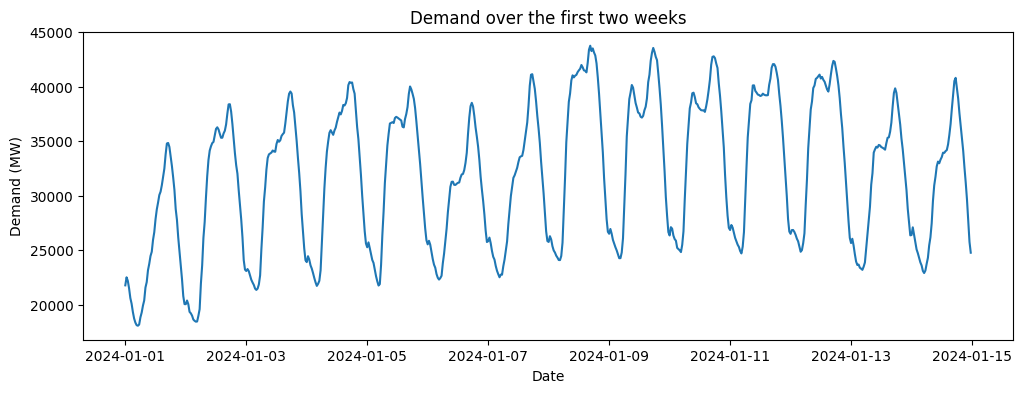

In [ ]:
# A two-week window, mostly just to eyeball the daily and weekly rhythm.
sample_data = demand_data.head(14 * 48)  # 14 days worth of half-hour periods
plt.figure(figsize=(12, 4))
plt.plot(sample_data["datetime"], sample_data["ND"])
plt.title("Demand over the first two weeks")
plt.xlabel("Date")
plt.ylabel("Demand (MW)")
plt.savefig("output/plots/sample_2weeks.png")
plt.show()

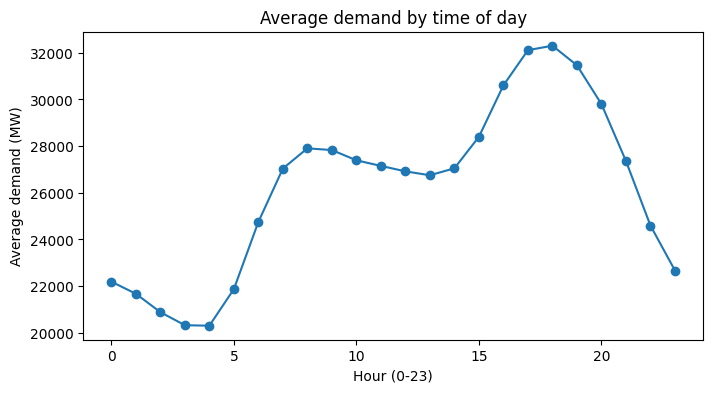

In [ ]:
# Average demand by hour of day -- this is where the morning and evening
# peaks should show up.
demand_data["hour"] = demand_data["datetime"].dt.hour
average_by_hour = demand_data.groupby("hour")["ND"].mean()
plt.figure(figsize=(8, 4))
plt.plot(average_by_hour.index, average_by_hour.values, marker="o")
plt.title("Average demand by time of day")
plt.xlabel("Hour (0-23)")
plt.ylabel("Average demand (MW)")
plt.savefig("output/plots/by_hour.png")
plt.show()

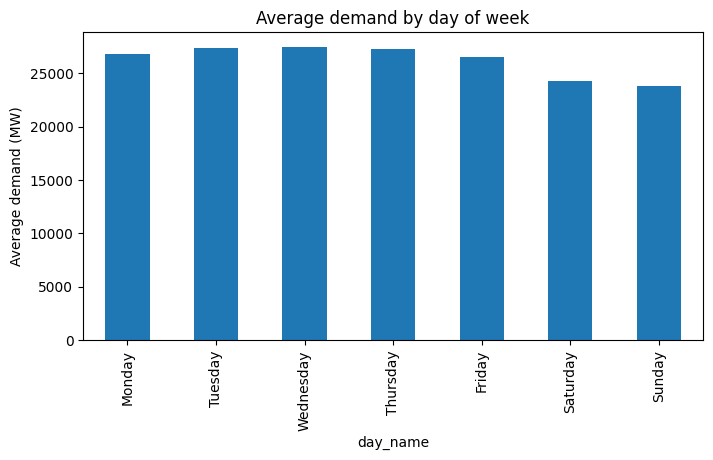

In [ ]:
# Same idea, but by day of the week -- weekdays vs weekends should look
# noticeably different.
demand_data["day_name"] = demand_data["datetime"].dt.day_name()
average_by_day = demand_data.groupby("day_name")["ND"].mean()
# Reindexing so the days come out Monday-to-Sunday instead of alphabetical.
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
average_by_day = average_by_day.reindex(day_order)
plt.figure(figsize=(8, 4))
average_by_day.plot(kind="bar")
plt.title("Average demand by day of week")
plt.ylabel("Average demand (MW)")
plt.savefig("output/plots/by_day.png")
plt.show()

<Figure size 1000x400 with 0 Axes>

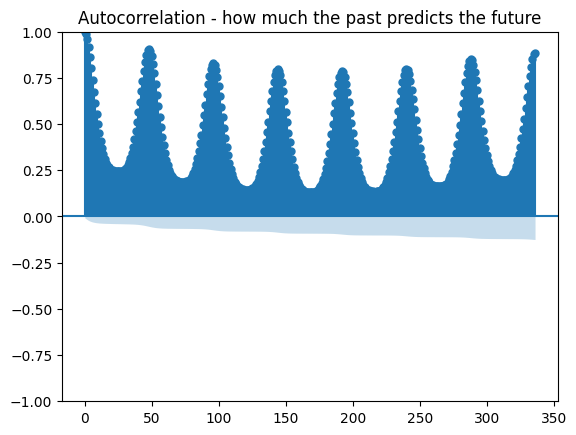

In [ ]:
# Autocorrelation: roughly, how much does knowing an earlier value tell me
# about a later one? This is part of the justification for using ARIMA as a
# baseline model later -- it leans directly on this kind of structure.
plt.figure(figsize=(10, 4))
plot_acf(demand_data["ND"].dropna(), lags=336)  # 336 = one week of half-hours
plt.title("Autocorrelation - how much the past predicts the future")
plt.savefig("output/plots/autocorrelation.png")
plt.show()

## Saving the clean version

This file is the baseline everything else in the project builds on. Once I
start injecting missing values, noise, and timestamp errors later, this is
the "before" every comparison gets measured against.

In [ ]:
final_columns = ["datetime", "SETTLEMENT_DATE", "SETTLEMENT_PERIOD", "ND", "TSD"]
demand_data[final_columns].to_csv("output/clean_demand_2024_2025.csv", index=False)

print("Done")


Done
